# Tutorial: UNAGI Iteration 2 Analysis Walkthrough

This notebook is an example walkthrough for the iteration-2 analysis job:
`analyze_20260218T040530Z_164db2d2`.

Audience:
- UNAGI users who want a reproducible way to inspect one analysis job output.

Prerequisites:
- UNAGI repo available locally.
- Python environment with `scanpy`, `pandas`, `matplotlib`, and `UNAGI` installed.

Learning goals:
- Locate and inspect iteration-2 analysis artifacts.
- Load available `dataset.h5ad` and `attribute.pkl` safely.
- Generate manuscript-style UMAP/composition figures.
- Extract and visualize perturbation ranking tables when available.


## 1. Setup

This cell sets deterministic runtime options and imports dependencies.


In [1]:
import os
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Avoid numba/joblib cache/permission issues in restricted environments.
os.environ.setdefault('NUMBA_CACHE_DIR', '/tmp/numba_cache')
os.environ.setdefault('JOBLIB_MULTIPROCESSING', '0')
Path(os.environ['NUMBA_CACHE_DIR']).mkdir(parents=True, exist_ok=True)


## 2. Define paths for this specific iteration-2 analysis


In [2]:
REPO_ROOT = Path('/mnt/md0/yumin/UNAGI_moved_20260211_152121')
TRAIN_JOB_ID = 'train_20260218T003238Z_97ae751c'
ANALYSIS_JOB_ID = 'analyze_20260218T040530Z_164db2d2'
ITERATION = 2

ANALYSIS_DIR = REPO_ROOT / 'outputs' / 'skill_jobs' / TRAIN_JOB_ID / 'analysis' / f'iter{ITERATION}' / ANALYSIS_JOB_ID / 'results'
TRAIN_ITER_DIR = REPO_ROOT / 'outputs' / 'skill_jobs' / TRAIN_JOB_ID / 'input' / str(ITERATION) / 'stagedata'
ANALYSIS_H5AD = ANALYSIS_DIR / 'dataset.h5ad'
ANALYSIS_ATTR = ANALYSIS_DIR / 'attribute.pkl'
FALLBACK_H5AD = TRAIN_ITER_DIR / 'dataset.h5ad'
FALLBACK_ATTR = TRAIN_ITER_DIR / 'attribute.pkl'
IDREM_DIR = ANALYSIS_DIR / 'idrem'
FIG_DIR = ANALYSIS_DIR / 'notebook_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

path_table = pd.DataFrame(
    {
        'path': [
            str(ANALYSIS_DIR),
            str(ANALYSIS_H5AD),
            str(ANALYSIS_ATTR),
            str(FALLBACK_H5AD),
            str(FALLBACK_ATTR),
            str(IDREM_DIR),
            str(FIG_DIR),
        ],
        'exists': [
            ANALYSIS_DIR.exists(),
            ANALYSIS_H5AD.exists(),
            ANALYSIS_ATTR.exists(),
            FALLBACK_H5AD.exists(),
            FALLBACK_ATTR.exists(),
            IDREM_DIR.exists(),
            FIG_DIR.exists(),
        ],
    }
)
display(path_table)


,path,exists
0,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
1,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
2,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
3,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
4,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
5,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True
6,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...,True


## 3. Snapshot of analysis output files


In [3]:
if ANALYSIS_DIR.exists():
    files = sorted([p for p in ANALYSIS_DIR.rglob('*') if p.is_file()])
    preview = pd.DataFrame({'file': [str(p.relative_to(ANALYSIS_DIR)) for p in files[:200]]})
    print(f'total files under results: {len(files)}')
    display(preview.head(40))
else:
    print('Analysis directory does not exist yet.')


total files under results: 143


,file
0,20progressionmarker_background.npy
1,attribute.pkl
2,dataset.h5ad
3,idrem/0-4n6n15-2-10.txt_viz/DREM.json
4,idrem/0-4n6n15-2-10.txt_viz/d3/LICENSE
5,idrem/0-4n6n15-2-10.txt_viz/d3/d3.js
6,idrem/0-4n6n15-2-10.txt_viz/d3/d3.min.js
7,idrem/0-4n6n15-2-10.txt_viz/d3.chart.sankey/d3...
8,idrem/0-4n6n15-2-10.txt_viz/d3.chart.sankey/d3...
9,idrem/0-4n6n15-2-10.txt_viz/d3.chart.sankey/sa...


## 4. Load AnnData with robust fallback

Priority:
1. Use analysis outputs (`results/dataset.h5ad`, `results/attribute.pkl`) if present.
2. Fallback to the staged training input for iteration 2.


In [4]:
import scanpy as sc
import io
from collections import OrderedDict
class _SafeUnpickler(pickle.Unpickler):
    """Unpickler that returns None for any object whose class cannot be
    reconstructed (e.g. signature mismatch after a code change)."""
    def load_reduce(self):
        try:
            return super().load_reduce()
        except TypeError:
            # discard the broken object; return None placeholder
            return None

def _safe_pickle_load(path):
    with open(path, 'rb') as f:
        try:
            return _SafeUnpickler(f).load()
        except Exception as e:
            print(f'Warning: could not load {path} with safe unpickler: {e}')
            return None

if ANALYSIS_H5AD.exists():
    adata = sc.read_h5ad(ANALYSIS_H5AD)
    adata_source = ANALYSIS_H5AD
else:
    adata = sc.read_h5ad(FALLBACK_H5AD)
    adata_source = FALLBACK_H5AD

attr_source = None
if ANALYSIS_ATTR.exists():
    with open(ANALYSIS_ATTR, 'rb') as f:
        uns_payload = pickle.load(f)
        uns_payload = dict(uns_payload)
    if isinstance(uns_payload, dict):
        adata.uns.update(uns_payload)
    attr_source = ANALYSIS_ATTR
elif FALLBACK_ATTR.exists():
    with open(FALLBACK_ATTR, 'rb') as f:
        uns_payload = pickle.load(f)
        uns_payload = dict(uns_payload)
        adata.uns.update(uns_payload)
    attr_source = FALLBACK_ATTR

print('adata source:', adata_source)
print('attribute source:', attr_source)
print('shape:', adata.shape)
print('obs columns (first 20):', list(adata.obs.columns)[:20])
print('layers:', list(adata.layers.keys()))
print('obsm:', list(adata.obsm.keys()))
print('uns keys (first 30):', list(adata.uns.keys())[:30])


adata source: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/dataset.h5ad
attribute source: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/attribute.pkl
shape: (27647, 2484)
obs columns (first 20): ['barcode', 'nUMI', 'nGene', 'percMito', 'percSpliced.v', 'percUnspliced.v', 'percAmbiguous.v', 'Sample.ID', 'Subject.ID', 'Sex', 'Age', 'Surface.Density', 'Percent.Tissue', 'Disease.Ident', 'nCount_RNA', 'final.ident', 'nFeature_RNA', 'nCount_integrated', 'nFeature_integrated', 'name.simple']
layers: ['geneWeight']
obsm: ['X_umap', 'embdedding', 'umap', 'z']
uns keys (first 30): ['clusterType', 'edges', 'topGene', 'top_gene_fold_change', 'top_gene_pvals_adj', 'data_pathway_overlap_genes', 'pathway_gene_len_dict', 'pathway_ranking', 'progressionMarkers', 'data_drug_overlap_genes', 'drug-

In [5]:
uns_payload.keys()

dict_keys(['clusterType', 'edges', 'topGene', 'top_gene_fold_change', 'top_gene_pvals_adj', 'data_pathway_overlap_genes', 'pathway_gene_len_dict', 'pathway_ranking', 'progressionMarkers', 'data_drug_overlap_genes', 'drug-gene_len_dict', 'random_background_perturbation_deltaD', 'pathway_perturbation_deltaD', 'pathway_perturbation_score', 'drug_perturbation_deltaD', 'drug_perturbation_score', 'hcmarkers'])

In [6]:
uns_payload.keys()

dict_keys(['clusterType', 'edges', 'topGene', 'top_gene_fold_change', 'top_gene_pvals_adj', 'data_pathway_overlap_genes', 'pathway_gene_len_dict', 'pathway_ranking', 'progressionMarkers', 'data_drug_overlap_genes', 'drug-gene_len_dict', 'random_background_perturbation_deltaD', 'pathway_perturbation_deltaD', 'pathway_perturbation_score', 'drug_perturbation_deltaD', 'drug_perturbation_score', 'hcmarkers'])

## 5. Basic summaries


In [7]:
summary = {}
summary['n_cells'] = adata.n_obs
summary['n_genes'] = adata.n_vars
for col in ['stage', 'leiden', 'ident', 'name.simple']:
    if col in adata.obs.columns:
        summary[f'unique_{col}'] = int(adata.obs[col].astype(str).nunique())

pd.DataFrame({'metric': list(summary.keys()), 'value': list(summary.values())})


,metric,value
0,n_cells,27647
1,n_genes,2484
2,unique_stage,4
3,unique_leiden,20
4,unique_ident,12
5,unique_name.simple,17


In [8]:
if 'stage' in adata.obs.columns:
    display(adata.obs['stage'].astype(str).value_counts().sort_index().rename('cells_per_stage').to_frame())
else:
    print('No stage column in adata.obs')


,cells_per_stage
stage,
0,13550
1,4195
2,3152
3,6750


## 6. Plot stage-wise UMAPs and composition bars

Uses the new manuscript-style plotting functions in `UNAGI.plotting`.


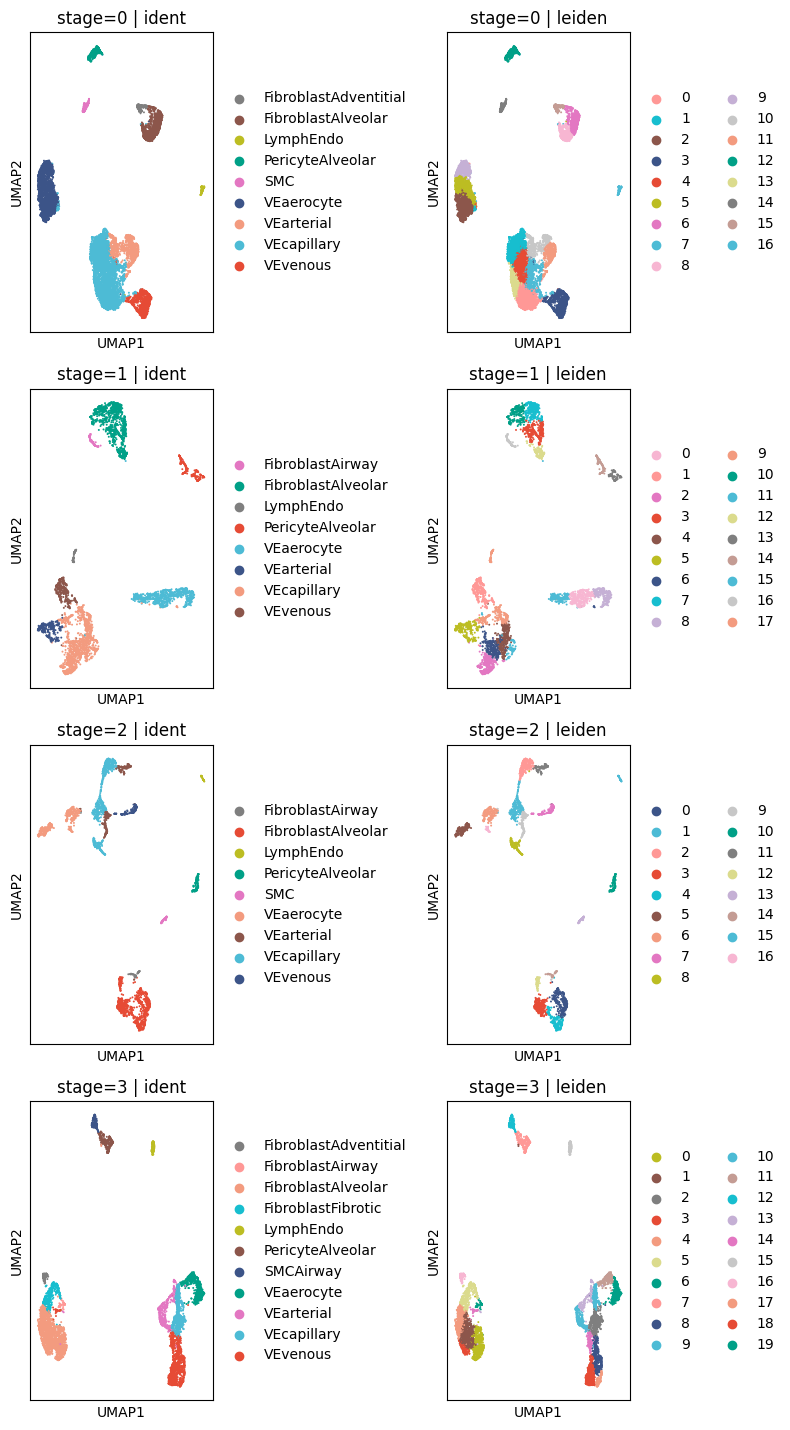

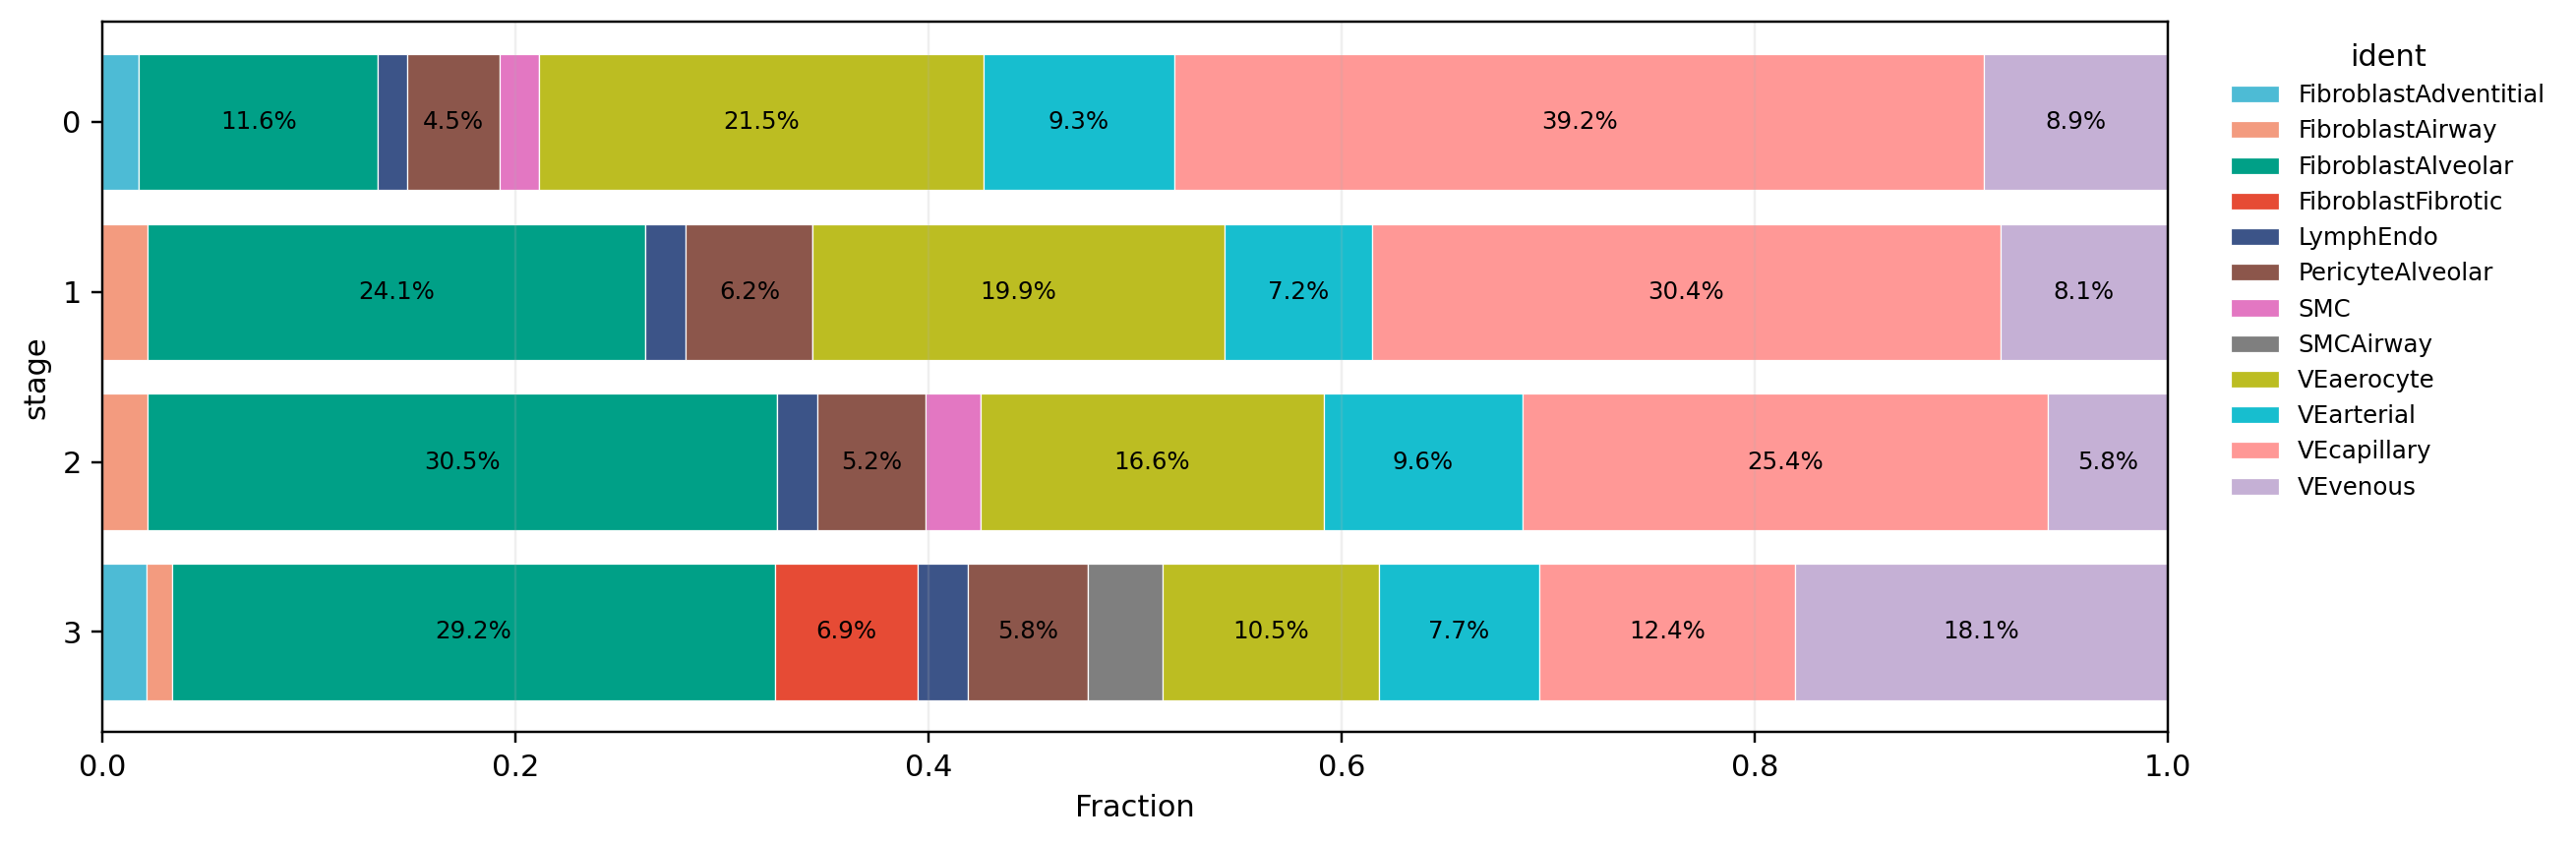

saved figures to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures


In [9]:
import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from UNAGI import plotting as up

stage_key = 'stage' if 'stage' in adata.obs.columns else None
cell_type_key = 'ident' if 'ident' in adata.obs.columns else ('name.simple' if 'name.simple' in adata.obs.columns else None)

if stage_key is None or cell_type_key is None:
    raise ValueError('Need stage + cell-type columns in adata.obs to run this section.')

# Ensure UMAP embedding key compatibility
if 'X_umap' not in adata.obsm and 'umap' in adata.obsm:
    adata.obsm['X_umap'] = adata.obsm['umap']

if 'X_umap' in adata.obsm:
    fig_umap, _ = up.plot_stage_umap_grid(
        adata,
        stage_key=stage_key,
        color_keys=(cell_type_key, 'leiden' if 'leiden' in adata.obs.columns else cell_type_key),
        show=False,
    )
    fig_umap.savefig(FIG_DIR / 'iter2_stage_umap_grid.png', dpi=100, bbox_inches='tight')
    plt.show()
else:
    print('UMAP embedding not found in adata.obsm; skipping UMAP panel.')

fig_comp, _ax_comp, _ctab = up.plot_stage_cell_type_composition(
    adata,
    cell_type_key=cell_type_key,
    stage_key=stage_key,
    show=False,
)
fig_comp.savefig(FIG_DIR / 'iter2_stage_composition.png', dpi=100, bbox_inches='tight')
plt.show()

print('saved figures to:', FIG_DIR)


## 7. Extract perturbation ranking tables (if available)


In [10]:
tables = {}
for mode in ['pathway', 'drug', 'single_gene', 'gene_combo']:
    try:
        df = up.extract_perturbation_table(
            adata,
            mode=mode,
            perturb_change=0.5,
            track='overall',
        )
        tables[mode] = df
        print(f'{mode}: {df.shape}')
        if not df.empty:
            display(df.head(10))
    except Exception as e:
        print(f'{mode}: not available -> {e}')


pathway: (1856, 5)


,pathways,perturbation score,pval_adjusted,drug_regulation,idrem_suggestion
0,NABA_MATRISOME,0.445780,7.771561e-16,"[ABI3BP, BMPER, CILP, COMP, CRIM1, CRISPLD1, C...","[ABI3BP:+, BMPER:+, CILP:-, COMP:-, CRIM1:-, C..."
1,REACTOME_DEVELOPMENTAL_BIOLOGY,0.413758,1.197931e-13,"[SPAG9, MAMLD1, CNTN1, EPHA3, NTN1, PRKCQ, FGF...","[SPAG9:+, MAMLD1:-, CNTN1:-, EPHA3:-, NTN1:-, ..."
2,REACTOME_SIGNALING_BY_GPCR,0.385133,7.569390e-12,"[CX3CL1, CASR, PTGER3, NPFFR2, CAMK2B, DGKG, C...","[CX3CL1:-, CASR:-, PTGER3:-, NPFFR2:+, CAMK2B:..."
3,REACTOME_NERVOUS_SYSTEM_DEVELOPMENT,0.381689,1.219147e-11,"[CNTN1, EPHA3, NTN1, PRKCQ, NTN4, SEMA3A, PAK3...","[CNTN1:-, EPHA3:-, NTN1:-, PRKCQ:-, NTN4:+, SE..."
4,REACTOME_POST_TRANSLATIONAL_PROTEIN_MODIFICATION,0.380674,1.401734e-11,"[CFTR, KLHL13, THSD7A, ASB4, PLAUR, BIRC3, VCA...","[CFTR:-, KLHL13:-, THSD7A:+, ASB4:-, PLAUR:-, ..."
5,REACTOME_METABOLISM_OF_LIPIDS,0.375182,2.962219e-11,"[ACSM3, ELOVL5, CYP24A1, MSMO1, ME1, PLPP1, AC...","[ACSM3:+, ELOVL5:-, CYP24A1:-, MSMO1:+, ME1:-,..."
6,NABA_MATRISOME_ASSOCIATED,0.368242,7.492906e-11,"[ANXA1, ANXA13, ANXA2, ANXA3, ANXA4, C1QTNF8, ...","[ANXA1:-, ANXA13:-, ANXA2:-, ANXA3:+, ANXA4:-,..."
7,WP_MALIGNANT_PLEURAL_MESOTHELIOMA,0.362415,1.609393e-10,"[PPARGC1A, YAP1, MCU, INSR, CDH2, FLT1, ITGA6,...","[PPARGC1A:+, YAP1:-, MCU:-, INSR:-, CDH2:-, FL..."
8,REACTOME_SIGNALING_BY_RECEPTOR_TYROSINE_KINASES,0.348422,9.547970e-10,"[ANOS1, IGF1, LAMC3, LAMA3, LAMC2, COL11A1, FG...","[ANOS1:+, IGF1:-, LAMC3:+, LAMA3:+, LAMC2:-, C..."
9,NABA_CORE_MATRISOME,0.347190,1.112679e-09,"[ABI3BP, BMPER, CILP, COMP, CRIM1, CRISPLD1, C...","[ABI3BP:+, BMPER:+, CILP:-, COMP:-, CRIM1:-, C..."


drug: (238, 5)


,compound,perturbation score,pval_adjusted,drug_regulation,idrem_suggestion
0,ibudilast,0.478451,0.000004,"[PDE10A:-, PDE3A:-, PDE4D:+]","[PDE10A:-, PDE3A:-, PDE4D:+]"
1,"dyphylline,rolipram,apremilast",0.400778,0.000224,[PDE4D:-],[PDE4D:+]
2,"doxofylline,roflumilast,cilomilast,Ro-20-1724,...",0.400778,0.000224,[PDE4D:+],[PDE4D:+]
3,vandetanib,0.398125,0.000253,"[EGFR:-, FLT1:-, KDR:+, TEK:+]","[EGFR:+, FLT1:+, KDR:+, TEK:+]"
4,regorafenib,0.369206,0.000897,"[FGFR2:+, FLT1:+, FRK:+, KDR:+, KIT:+, TEK:+]","[FGFR2:-, FLT1:+, FRK:-, KDR:+, KIT:-, TEK:+]"
5,canertinib,0.368896,0.000909,"[EGFR:+, ERBB4:-]","[EGFR:+, ERBB4:+]"
6,clozapine,0.366135,0.001019,"[CHRM2:-, CHRM3:-, ADRA1A:-, HRH1:+]","[CHRM2:+, CHRM3:+, ADRA1A:+, HRH1:+]"
7,semaxanib,0.362778,0.001170,"[FLT1:+, KDR:-, KIT:+]","[FLT1:+, KDR:+, KIT:-]"
8,"indometacin,mesalazine",0.352262,0.001783,"[PPARG:+, PTGS2:-]","[PPARG:+, PTGS2:-]"
9,"belinostat,apicidin,SB-939",0.348410,0.002072,[HDAC9:+],[HDAC9:-]


single_gene: not available -> 'Missing single_gene_perturbation_score in adata.uns'
gene_combo: not available -> 'Missing two_genes_perturbation_score in adata.uns'


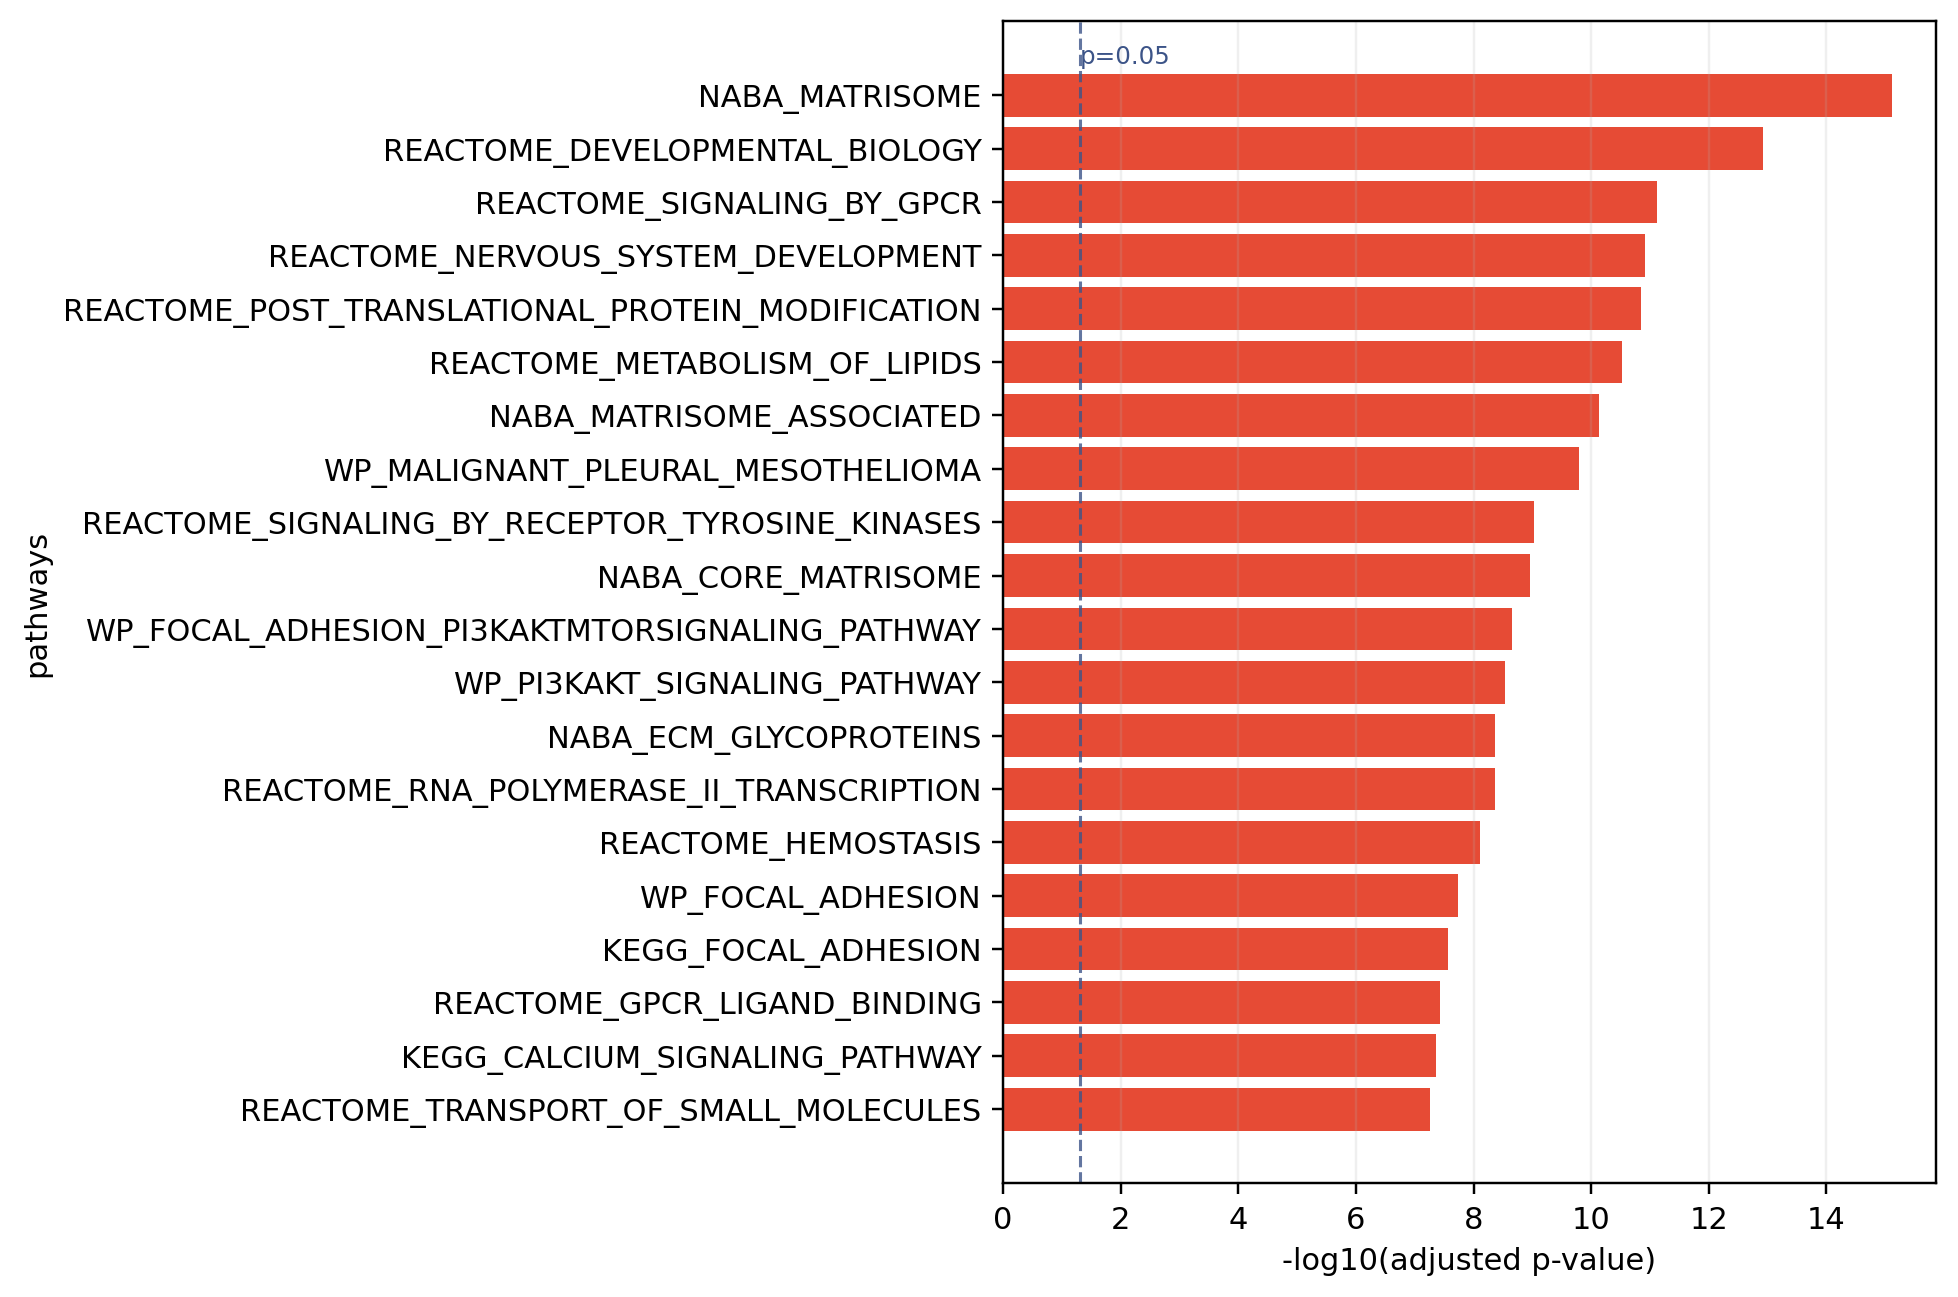

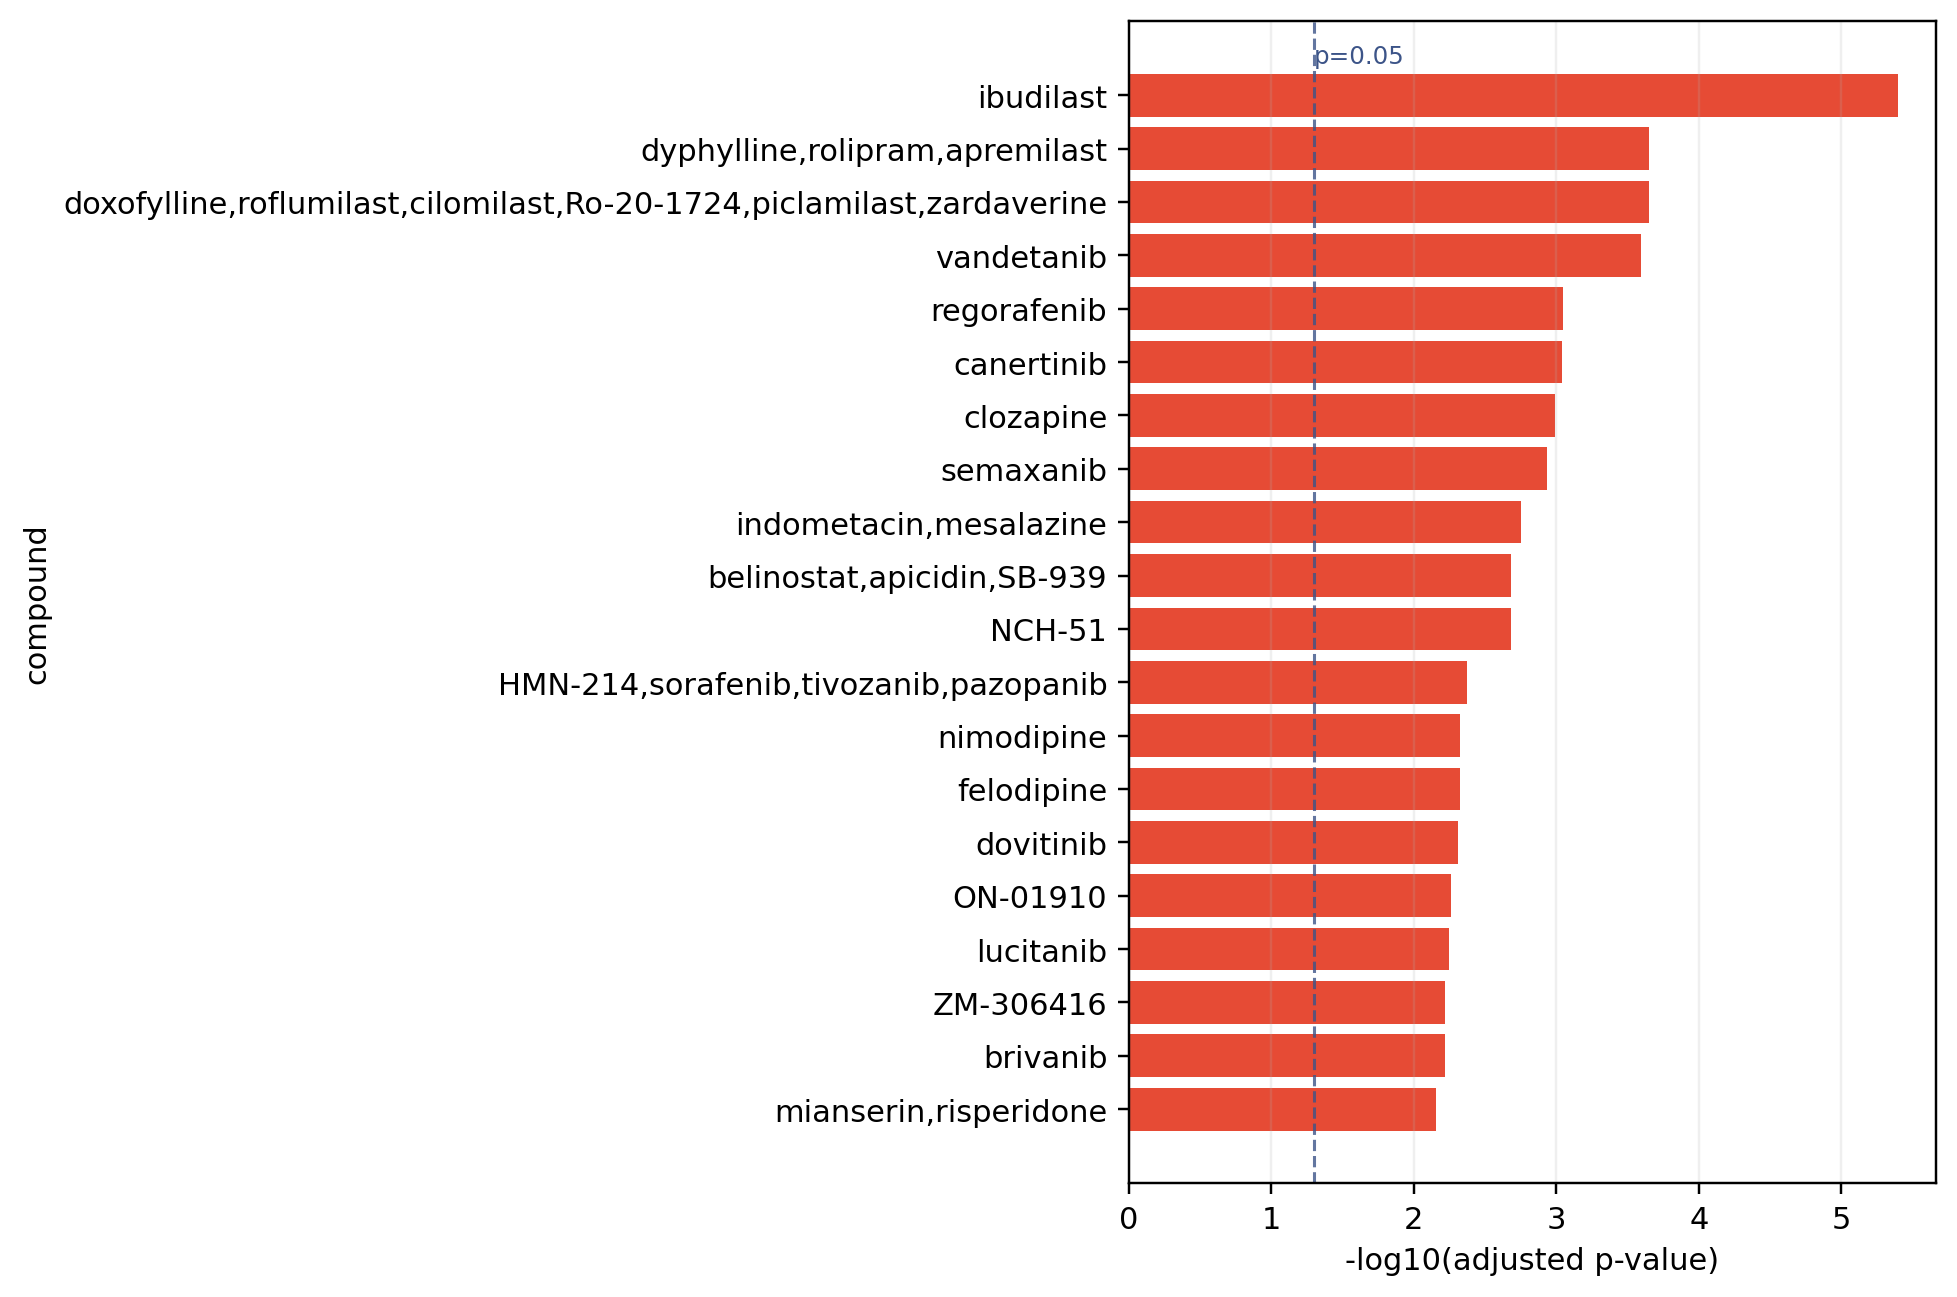

saved perturbation bar plots (if available) to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures


In [11]:
for mode in ['pathway', 'drug']:
    df = tables.get(mode)
    if df is None or df.empty:
        continue
    fig, _ax, _work = up.plot_perturbation_ranked_bar(df, top_n=20, show=False)
    fig.savefig(FIG_DIR / f'iter2_{mode}_ranked_bar.png', dpi=100, bbox_inches='tight')
    plt.show()

print('saved perturbation bar plots (if available) to:', FIG_DIR)


## 8. Figure 3/4-style marker and temporal dynamics plots

These views follow the marker and temporal-dynamics visualization concepts in the UNAGI manuscript:
https://www.nature.com/articles/s41551-025-01423-7


dynamic marker trajectory track used: 0-4n6n15-2-10


,gene,log2fc,rank,stage0,stage1,stage2,stage3,qval,track,direction
0,APLNR,0.669752,1,0.729635,1.054282,0.999232,1.399388,0.000061,0-4n6n15-2-10,increasing
1,THBD,0.613481,2,1.067851,1.332890,1.269159,1.681331,0.000222,0-4n6n15-2-10,increasing
2,EDN1,0.513326,3,0.484478,0.590499,0.819858,0.997804,0.003228,0-4n6n15-2-10,increasing
3,SPARC,0.448706,4,0.515781,0.792329,0.942378,0.964487,0.013062,0-4n6n15-2-10,increasing
4,PTCHD4,0.439853,5,0.288641,0.827409,0.496158,0.728493,0.012925,0-4n6n15-2-10,increasing
5,CCN2,0.419427,6,0.233500,0.334611,0.547700,0.652927,0.017303,0-4n6n15-2-10,increasing
6,SLC6A4,0.412891,7,0.993311,1.259626,1.111898,1.406202,0.017176,0-4n6n15-2-10,increasing
7,PLAT,0.400644,8,0.454316,0.851927,0.790395,0.854961,0.019661,0-4n6n15-2-10,increasing
8,MMP19,0.395632,9,0.034476,0.191441,0.138325,0.430108,0.019462,0-4n6n15-2-10,increasing
9,LUM,0.392605,10,0.081885,0.278656,0.126730,0.474490,0.018679,0-4n6n15-2-10,increasing


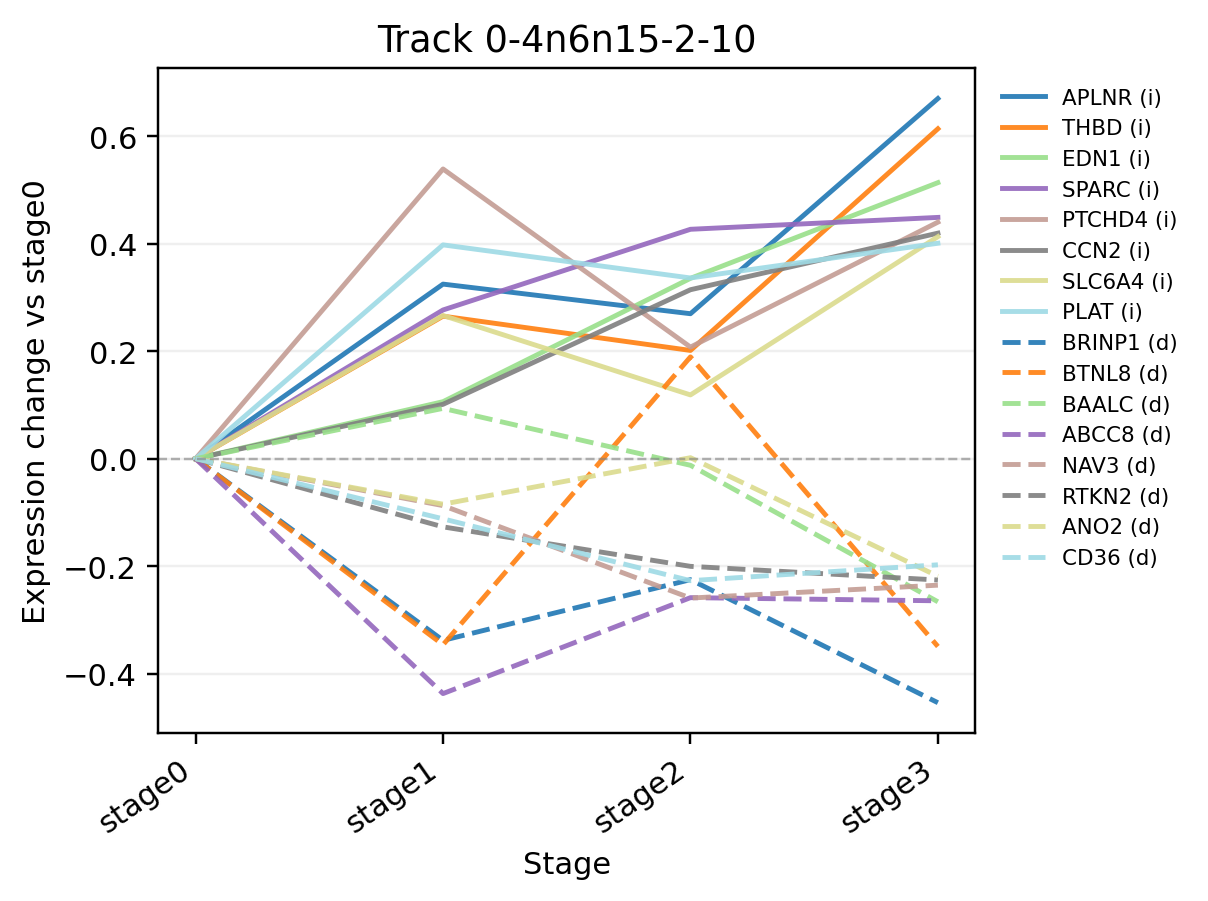

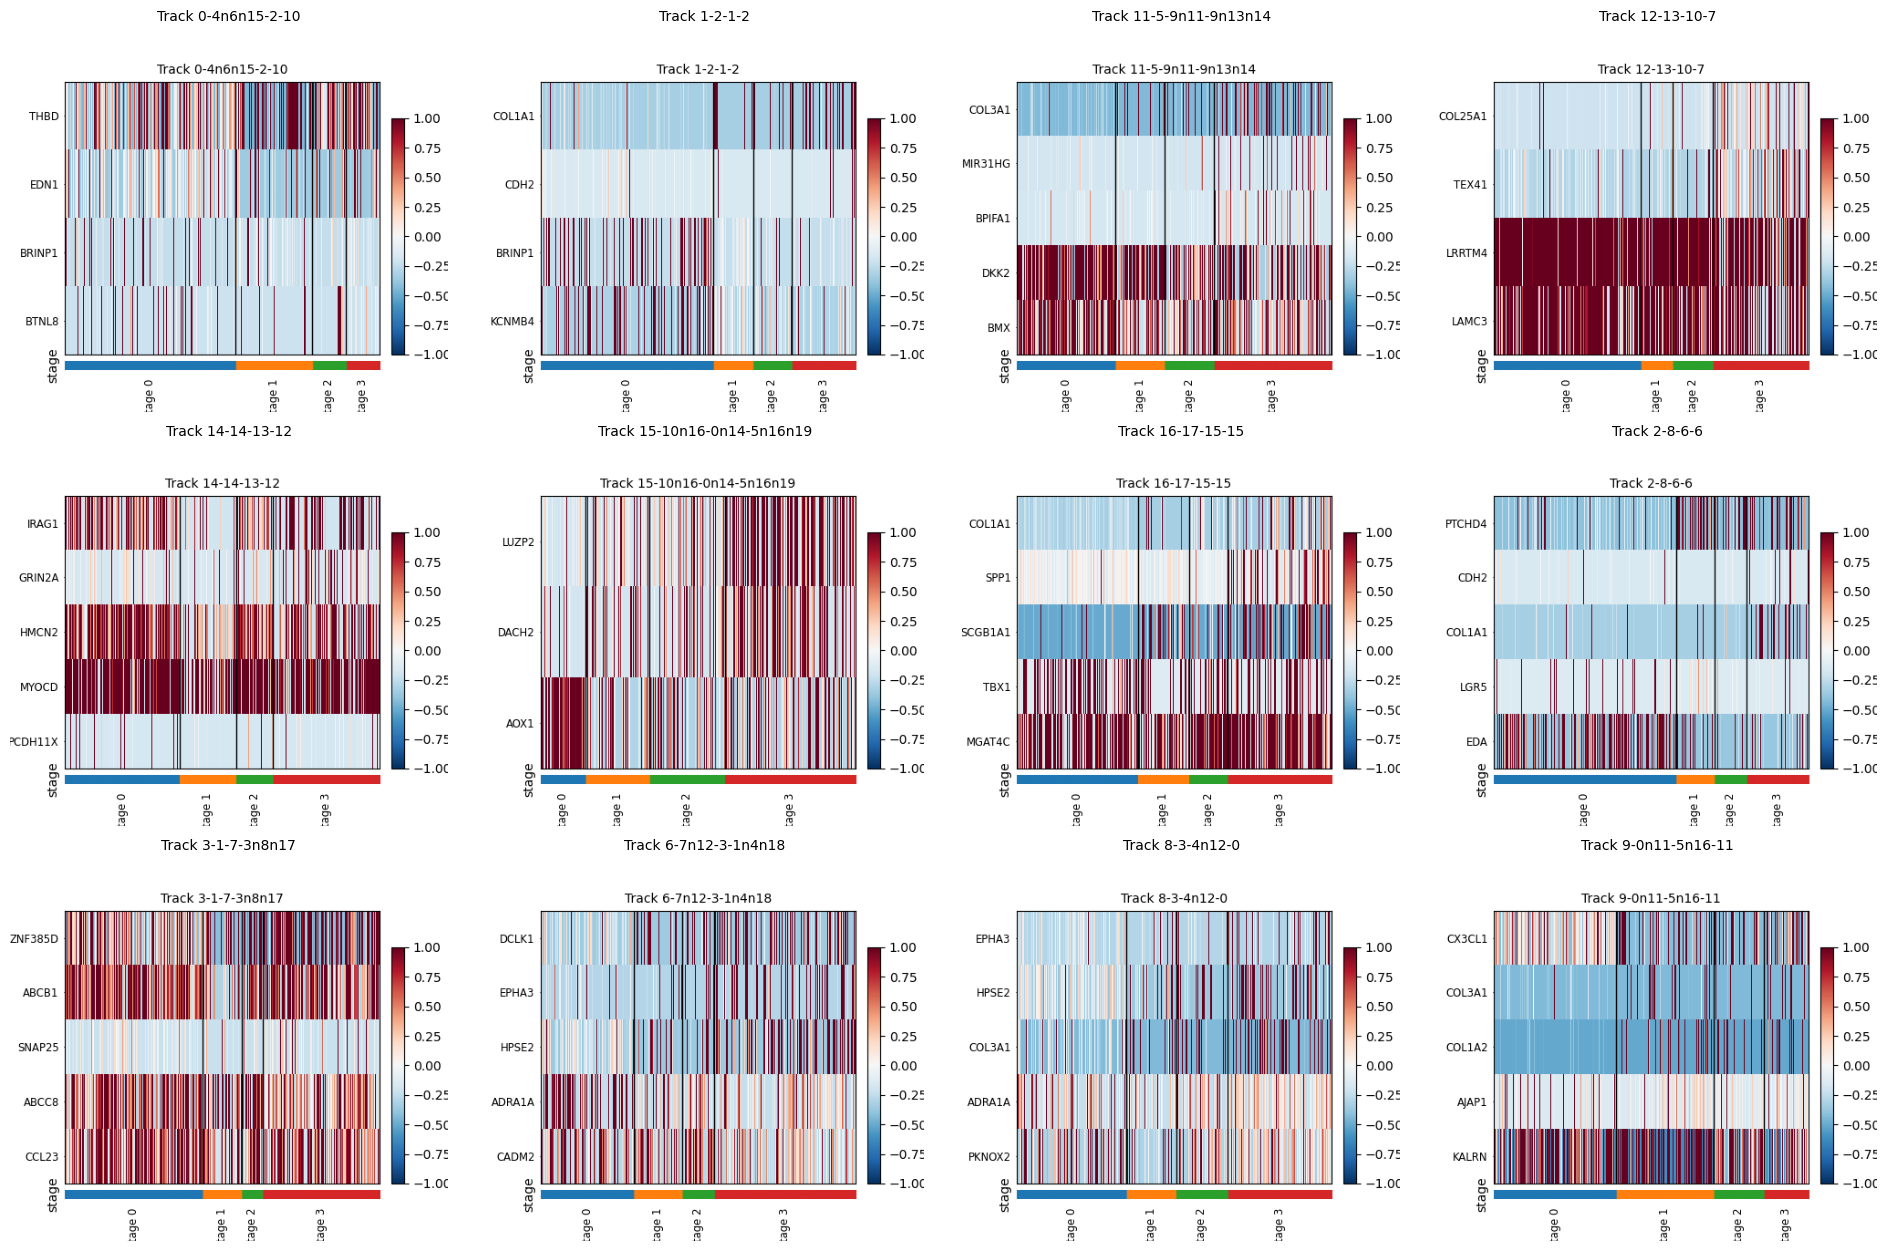

saved dynamic marker plots to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures
trajectory long table shape: (64, 6)
track panel summary shape: (12, 3)


In [12]:
if 'progressionMarkers' in adata.uns and adata.uns['progressionMarkers']:
    track_candidates = sorted([str(k) for k in adata.uns['progressionMarkers'].keys()])
    target_track = track_candidates[0]
    print('dynamic marker trajectory track used:', target_track)

    dm_table = up.extract_dynamic_marker_table(
        adata,
        track=target_track,
        direction='increasing',
        top_n=12,
    )
    display(dm_table.head(12))

    fig_dyn, _, dyn_long = up.plot_dynamic_marker_trajectories(
        adata,
        tracks=[target_track],
        directions=('increasing', 'decreasing'),
        top_n=8,
        normalize_to_stage0=True,
        show=False,
    )
    fig_dyn.savefig(FIG_DIR / 'iter2_dynamic_marker_trajectories.png', dpi=100, bbox_inches='tight')
    plt.show()

    # Example-style dynamic marker heatmap (Fig. 4A): all tracks, 3-5 markers per track.
    markers_per_track = 5  # set to 3 for a compact panel
    fig_height = max(10, 0.33 * len(track_candidates) * markers_per_track)
    fig_dyn_hm, _, dyn_panels = up.plot_dynamic_marker_heatmap_track_panels(
        adata,
        tracks=None,  # all tracks, one subplot per track
        directions=('increasing', 'decreasing'),
        top_n=markers_per_track,
        per_track_total=True,
        protein_coding_only=True,
        require_genes_in_var=True,
        noncoding_prefixes=('AC', 'AL', 'AP', 'LINC'),
        exclude_dot_genes=True,
        row_zscore=True,
        stage_key='stage',
        cluster_key='leiden',
        cell_groupby='stage',
        restrict_to_track_cells=True,
        cmap='RdBu_r',
        vmin=-1,
        vmax=1,
        ncols=4,
        figsize_per_panel=(4.8, 4.2),
        dpi=100,
        show=False,
    )
    fig_dyn_hm.savefig(FIG_DIR / 'iter2_dynamic_marker_heatmap.png', dpi=100, bbox_inches='tight')
    plt.show()

    print('saved dynamic marker plots to:', FIG_DIR)
    print('trajectory long table shape:', dyn_long.shape)
    print('track panel summary shape:', dyn_panels.shape)
else:
    print("No adata.uns['progressionMarkers'] available yet.")


hierarchical marker target: {'stage': '0', 'cluster': '0', 'level': '0'}


,pvals_adj,scores,log_fold_changes,Mean_compared_clusters,Mean_selected_clusters,gene
0,9.261520e-186,29.242502,0.667818,0.400033,1.067851,THBD
1,1.073076e-114,22.946461,0.654142,0.482545,1.136688,FCN3
2,3.510824e-183,29.036760,0.611388,0.402079,1.013467,F2RL3
3,9.787629e-158,26.931263,0.556008,0.471962,1.027970,AKAP12
4,0.000000e+00,38.386150,0.497218,0.232417,0.729635,APLNR
5,7.725569e-100,21.392921,0.495700,0.497612,0.993311,SLC6A4
6,2.188470e-60,16.582422,0.448411,0.438330,0.886741,NRXN3
7,1.061567e-61,16.764977,0.411181,0.604512,1.015693,VWF
8,6.118063e-63,16.934904,0.400295,0.500109,0.900404,KIAA1217
9,1.162288e-97,21.155037,0.381428,0.600083,0.981511,EPAS1


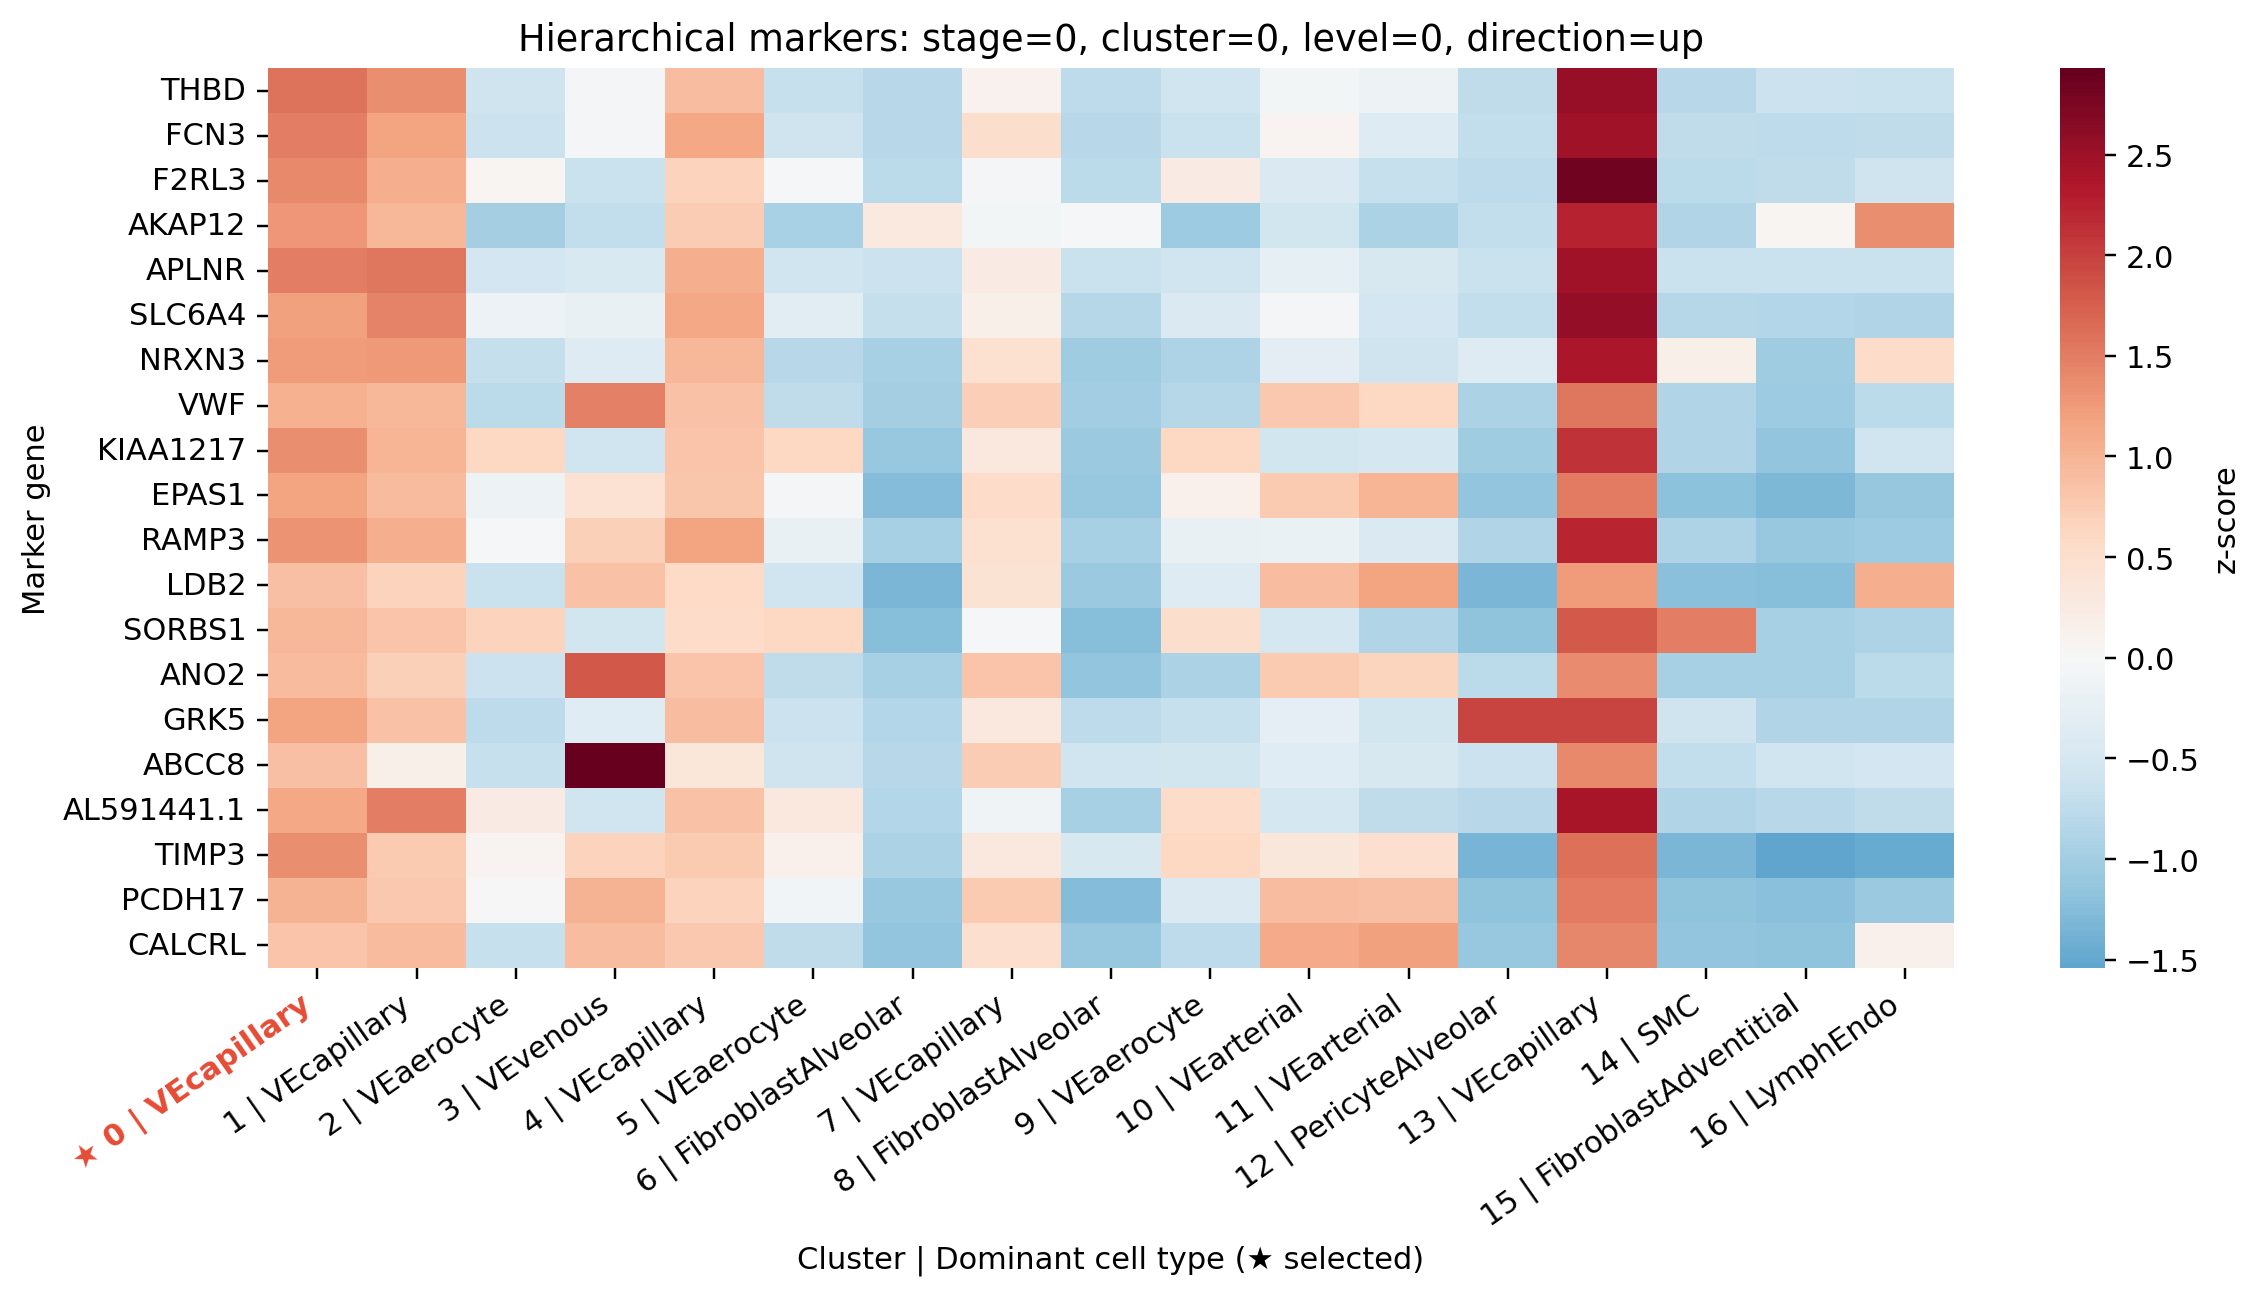

saved hierarchical marker heatmap to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures
hierarchical matrix shape: (20, 17)


In [13]:
cluster_key = 'leiden' if 'leiden' in adata.obs.columns else None

if 'hcmarkers' in adata.uns and adata.uns['hcmarkers'] and cluster_key is not None:
    stage_candidates = sorted([str(k) for k in adata.uns['hcmarkers'].keys()])
    h_stage = stage_candidates[0]
    h_markers = adata.uns['hcmarkers'][h_stage]['markers']
    h_cluster = next(iter(h_markers.keys()))
    h_level = next(iter(h_markers[h_cluster].keys()))

    print('hierarchical marker target:', {'stage': h_stage, 'cluster': h_cluster, 'level': h_level})

    hm_table = up.extract_hierarchical_marker_table(
        adata,
        stage=h_stage,
        cluster=h_cluster,
        level=h_level,
        direction='up',
        top_n=20,
    )
    display(hm_table.head(20))

    fig_hm, _, hm_matrix, _ = up.plot_hierarchical_marker_branch_heatmap(
        adata,
        stage=h_stage,
        cluster=h_cluster,
        level=h_level,
        direction='up',
        top_n=20,
        stage_key=stage_key,
        cluster_key=cluster_key,
        celltype_key=cell_type_key,
        show=False,
    )
    fig_hm.savefig(
        FIG_DIR / f'iter2_hierarchical_marker_heatmap_stage{h_stage}_cluster{h_cluster}_level{h_level}.png',
        dpi=100,
        bbox_inches='tight'
    )
    plt.show()

    print('saved hierarchical marker heatmap to:', FIG_DIR)
    print('hierarchical matrix shape:', hm_matrix.shape)
else:
    print("No adata.uns['hcmarkers'] available or missing leiden clusters.")


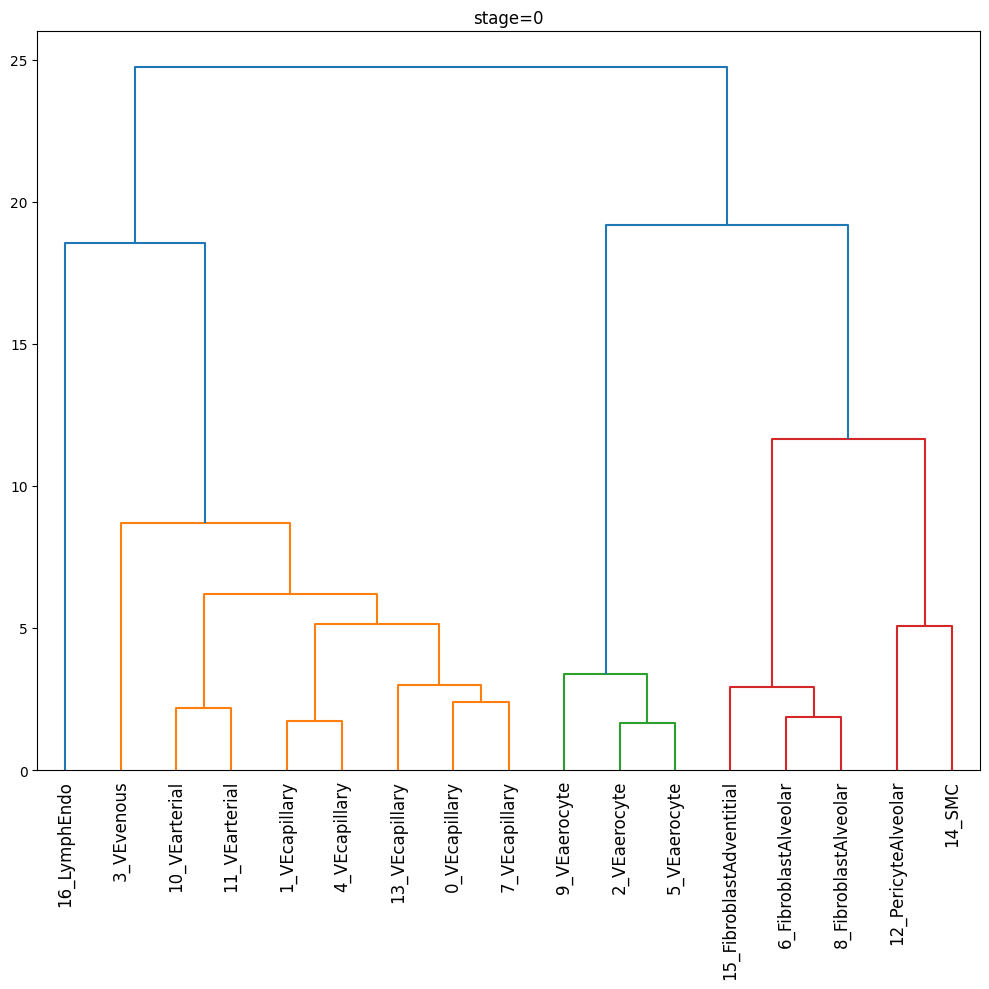

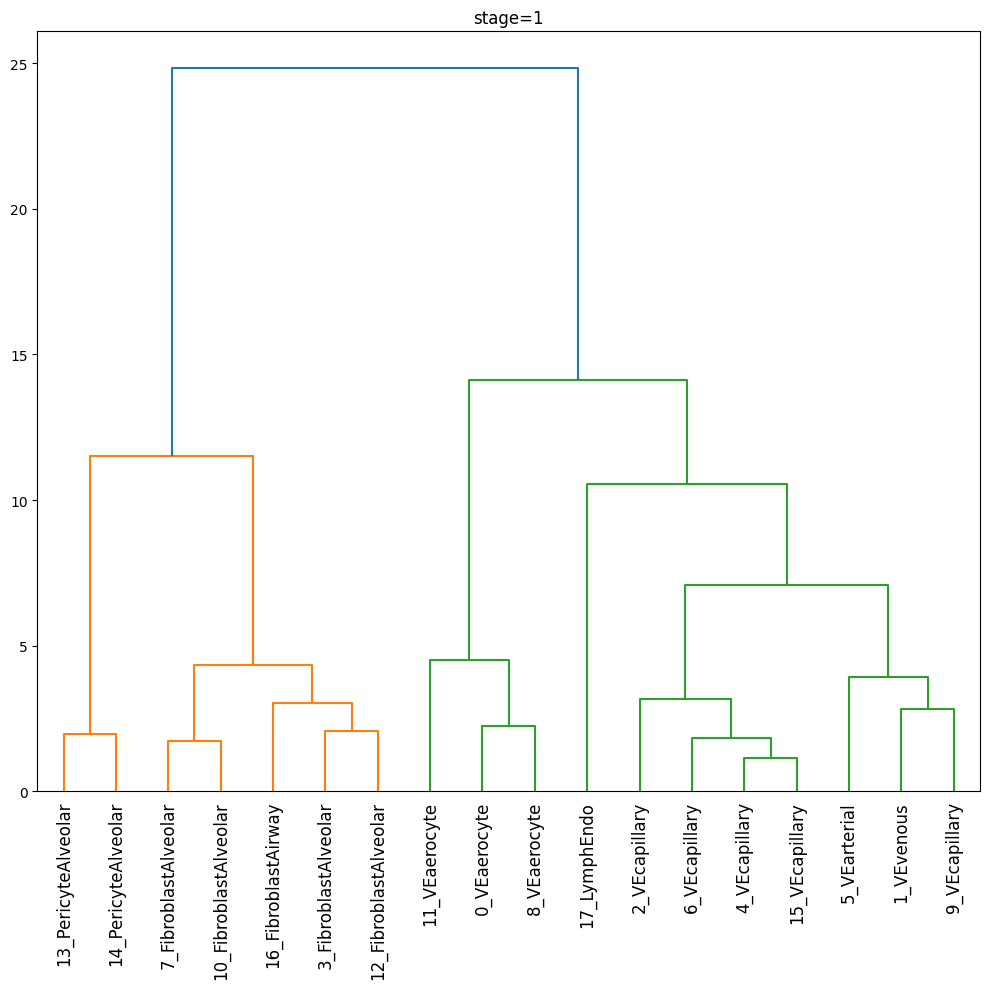

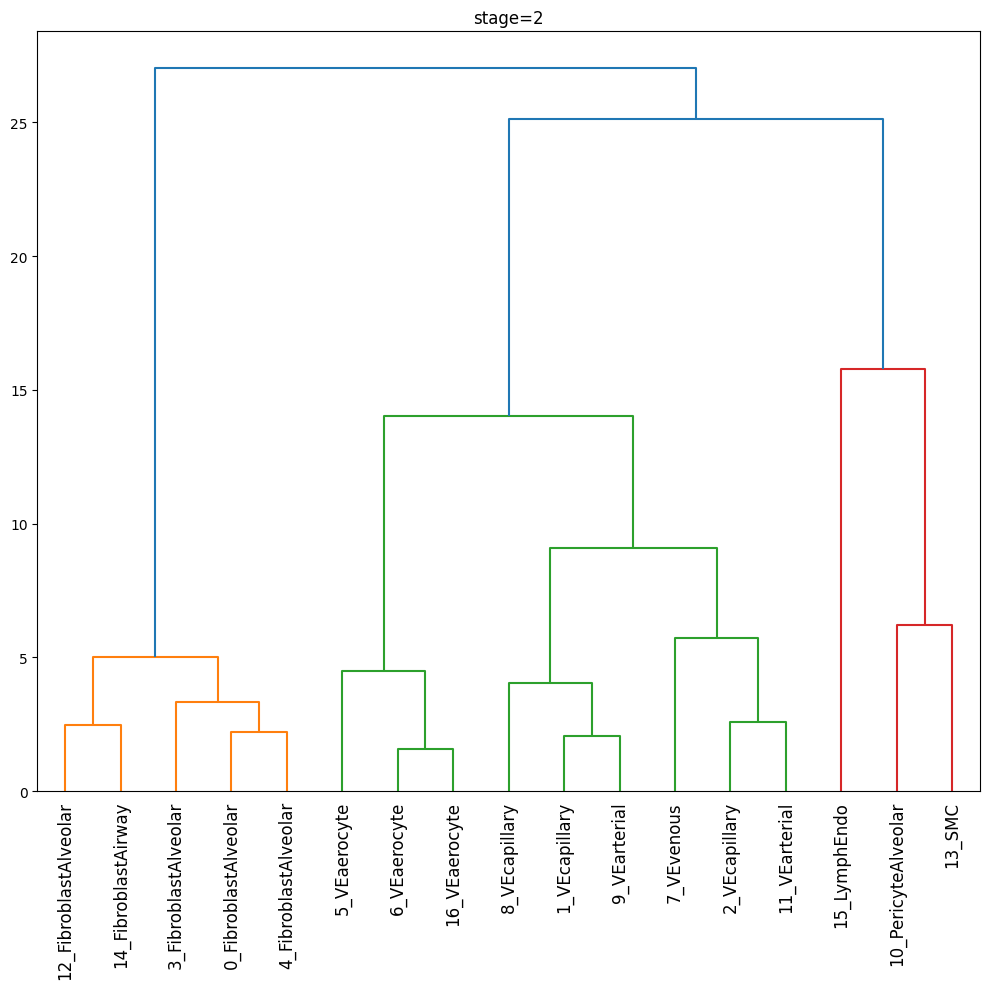

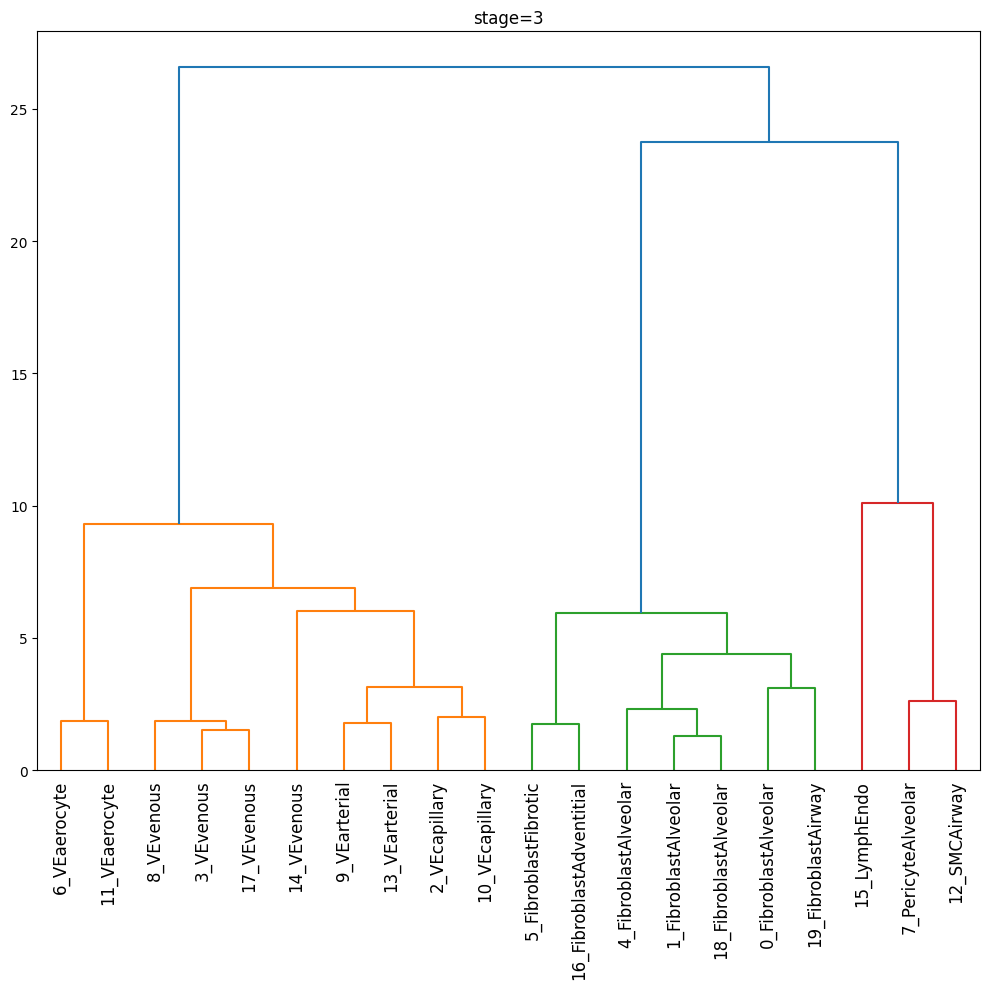

saved dendrogram pdfs to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures
['dendrogram_stage_0.pdf', 'dendrogram_stage_1.pdf', 'dendrogram_stage_2.pdf', 'dendrogram_stage_3.pdf']


In [14]:
if 'hcmarkers' in adata.uns and adata.uns['hcmarkers'] and stage_key is not None and cell_type_key is not None:
    import shutil
    from pathlib import Path

    before = set(Path('.').glob('dendrogram_stage_*.pdf'))
    up.plot_hc_dendrogram(
        adata,
        stage_key=stage_key,
        celltype_key=cell_type_key,
        save=True,
        dpi=100,
    )
    after = set(Path('.').glob('dendrogram_stage_*.pdf'))
    produced = sorted(after - before)
    if not produced:
        produced = sorted(after)

    saved = []
    for pdf in produced:
        target = FIG_DIR / pdf.name
        if target.exists():
            target.unlink()
        shutil.move(str(pdf), str(target))
        saved.append(target.name)

    if saved:
        print('saved dendrogram pdfs to:', FIG_DIR)
        print(saved)
    else:
        print('Dendrogram plotting ran, but no pdf files were found to move.')
else:
    print("No adata.uns['hcmarkers'] available for dendrogram plotting.")


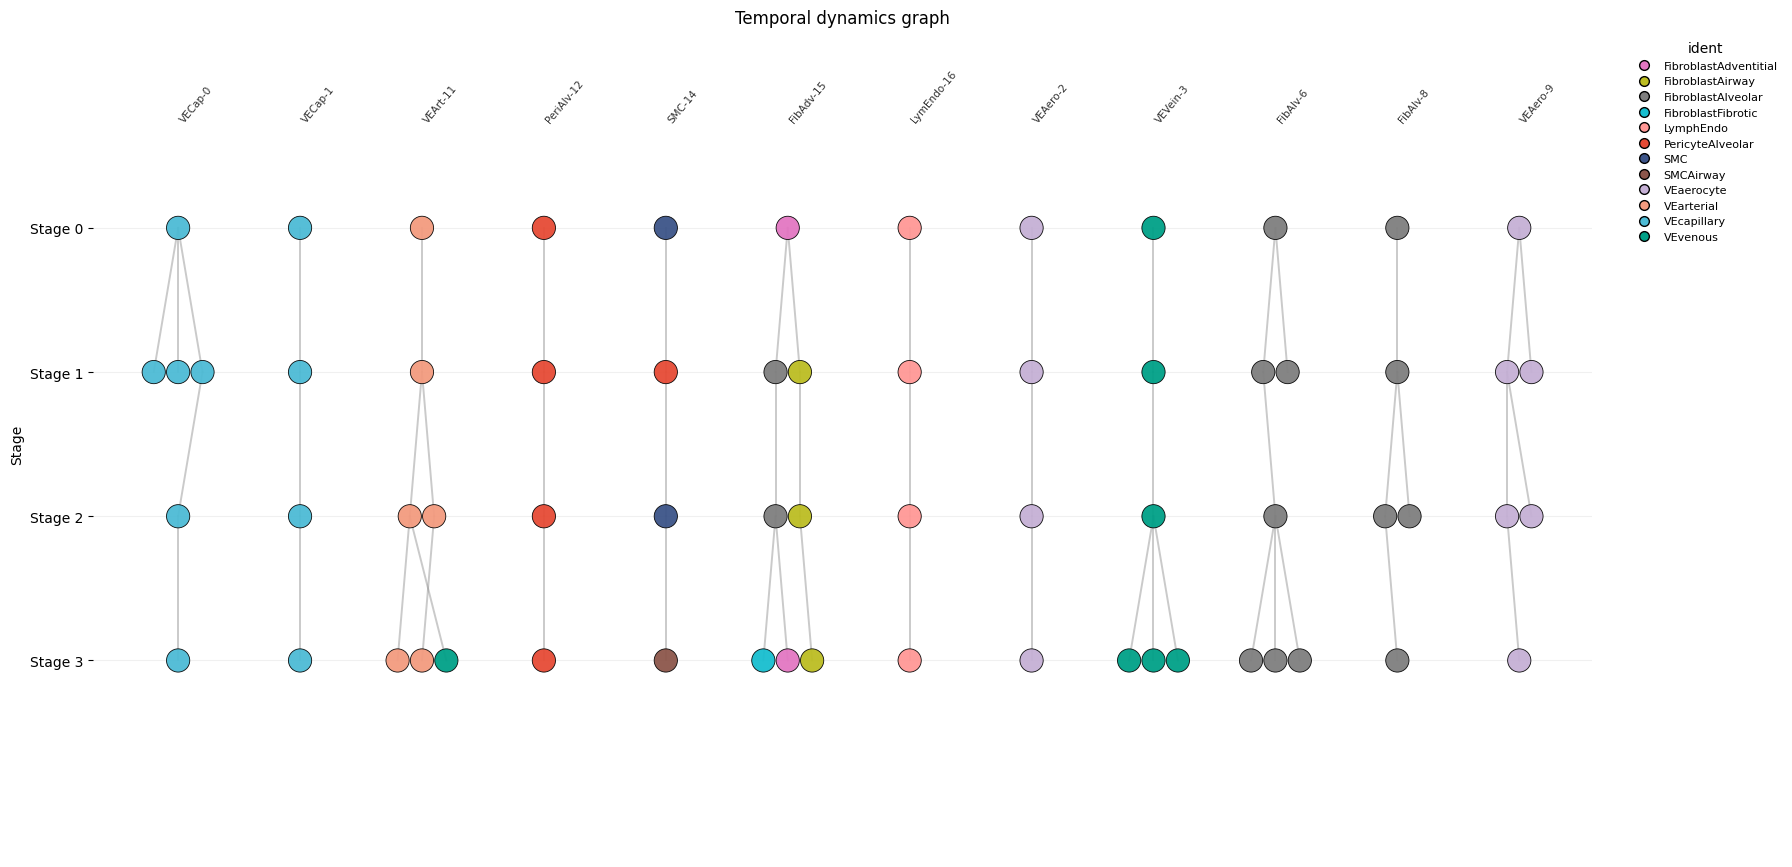

saved temporal dynamics graph to: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/notebook_figures


In [15]:
if 'edges' in adata.uns and stage_key is not None and 'leiden' in adata.obs.columns:
    fig_td, _, temporal_nodes, temporal_edges = up.plot_temporal_dynamics_graph(
        adata,
        edges_key='edges',
        stage_key=stage_key,
        cluster_key='leiden',
        celltype_key=cell_type_key,
        layout_mode='track_separated',
        track_source='progression_markers',
        max_tracks=None,
        show_node_labels=False,
        show=False,
    )
    fig_td.savefig(FIG_DIR / 'iter2_temporal_dynamics_graph.png', dpi=100, bbox_inches='tight')
    plt.show()

    print('saved temporal dynamics graph to:', FIG_DIR)
else:
    print("No adata.uns['edges'] available or required obs columns missing.")


## 9. Inspect generated iDREM visualization artifacts


In [16]:
if IDREM_DIR.exists():
    viz_dirs = sorted([p for p in IDREM_DIR.glob('*_viz') if p.is_dir()])
    print('idrem visualization folders:', len(viz_dirs))
    if viz_dirs:
        rows = []
        for p in viz_dirs:
            rows.append(
                {
                    'viz_dir': p.name,
                    'has_html': (p / 'idrem_result.html').exists(),
                    'has_drem_json': (p / 'DREM.json').exists(),
                }
            )
        display(pd.DataFrame(rows).head(20))
        first_html = viz_dirs[0] / 'idrem_result.html'
        if first_html.exists():
            print('example html:', first_html)
else:
    print('No idrem directory found yet.')


idrem visualization folders: 12


,viz_dir,has_html,has_drem_json
0,0-4n6n15-2-10.txt_viz,True,True
1,1-2-1-2.txt_viz,True,True
2,11-5-9n11-9n13n14.txt_viz,True,True
3,12-13-10-7.txt_viz,True,True
4,14-14-13-12.txt_viz,True,True
5,15-10n16-0n14-5n16n19.txt_viz,True,True
6,16-17-15-15.txt_viz,True,True
7,2-8-6-6.txt_viz,True,True
8,3-1-7-3n8n17.txt_viz,True,True
9,6-7n12-3-1n4n18.txt_viz,True,True


example html: /mnt/md0/yumin/UNAGI_moved_20260211_152121/outputs/skill_jobs/train_20260218T003238Z_97ae751c/analysis/iter2/analyze_20260218T040530Z_164db2d2/results/idrem/0-4n6n15-2-10.txt_viz/idrem_result.html


## 10. Optional: check analysis job status from notebook


In [17]:
import subprocess

cmd = [
    'python',
    str(REPO_ROOT / 'skills' / 'unagi-workflow-orchestrator' / 'scripts' / 'unagi_job.py'),
    'status',
    ANALYSIS_JOB_ID,
    '--repo-root',
    str(REPO_ROOT),
]

res = subprocess.run(cmd, capture_output=True, text=True)
print('return code:', res.returncode)
if res.stdout.strip():
    payload = json.loads(res.stdout)
    display(pd.DataFrame([{
        'job_id': payload.get('job_id'),
        'status': payload.get('status'),
        'started_at': payload.get('started_at'),
        'finished_at': payload.get('finished_at'),
        'analysis_output_dir': payload.get('analysis_output_dir'),
    }]))
else:
    print(res.stderr)


return code: 0


,job_id,status,started_at,finished_at,analysis_output_dir
0,analyze_20260218T040530Z_164db2d2,succeeded,2026-02-18T04:05:30+00:00,2026-02-18T09:15:49+00:00,/mnt/md0/yumin/UNAGI_moved_20260211_152121/out...


## 11. Notes

- If this analysis job is still running, `results/dataset.h5ad` and `results/attribute.pkl` may not exist yet.
- In that case, this notebook still works in fallback mode using the iteration-2 staged input dataset.
- Re-run this notebook after the analysis finishes to access full perturbation tables and complete outputs.
